In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [4]:
from src.engine import Package, Truck, State, Placement

pkgs = [
   Package("A", 3, 4, 1, 60, 5, False, 3),
   Package("B", 2, 2, 2, 40, 3, True, 1),
]
trucks = [Truck(0, 10, 20, 5, 500)]
s = State(pkgs, trucks, init="random")

s.set_placement("A", Placement(truck_id=0))
print(s)

print("Packages in Truck 0: ", s.get_packages_in_truck(0)) 
print("Packages outside: ", s.get_packages_outside()) 

print()

new_s = s.copy()
new_s.set_placement("B", Placement(truck_id=0, x=5, y=5, z=0, orientation=2))
print(new_s)

print("Packages outside in original state: ", len(s.get_packages_outside()))   # still 1 — clone is independent
print("Packages outside in new state: ", len(new_s.get_packages_outside()))  # 0

State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck 0 at (0, 0, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned

Packages in Truck 0:  [(Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3), Truck 0 at (0, 0, 0))]
Packages outside:  [Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1)]

State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck 0 at (0, 0, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck 0 at (5, 5, 0)

Packages outside in original state:  1
Packages outside in new state:  0


State:
  Package 01 (dim=5x6x1, weight=20, value=70, fragile=True, eta=2) -> Unassigned
  Package 02 (dim=3x1x2, weight=10, value=50, fragile=False, eta=5) -> Unassigned
  Package 03 (dim=2x7x1, weight=5, value=60, fragile=False, eta=1) -> Unassigned

State:
  Package 01 (dim=5x6x1, weight=20, value=70, fragile=True, eta=2) -> Truck Truck2 at (0, 3, 0)
  Package 02 (dim=3x1x2, weight=10, value=50, fragile=False, eta=5) -> Truck Truck1 at (6, 11, 0)
  Package 03 (dim=2x7x1, weight=5, value=60, fragile=False, eta=1) -> Truck Truck1 at (2, 15, 0)



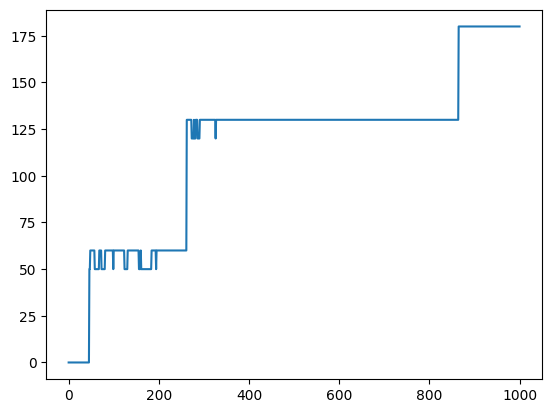

In [ ]:
from src.engine import *
from src.solvers.simulated_annealing import SimulatedAnnealing, GeometricSchedule
import matplotlib.pyplot as plt

# Define packages
pkgs = [
    Package("01", 5, 6, 1, 70, 20, True, 2),
    Package("02", 3, 1, 2, 50, 10, False, 5),
    Package("03", 2, 7, 1, 60, 5, False, 1)
]

# Define trucks
trucks = [Truck("Truck1", 30, 40, 50, 15), Truck("Truck2", 10, 30, 40, 25)]

state = State(pkgs, trucks, init="random_feasible")
print(state)
is_valid(state)
obj = MaxValueObjective()
schedule = GeometricSchedule(100, 0.99)

solver_sa = SimulatedAnnealing(obj, schedule, max_iterations=1000)
results = solver_sa.solve(state)
print(results.final_state)

plt.plot(results.objective_history)